# Passaggio 6: backtest di tutte le varianti dell'agente (solo train)

**Domanda.** Le notizie migliorano la strategia di pairs trading? Si confronta la versione **A** (tutti i segnali entrano) con le varianti dell'agente di notizie: **B** può bloccare un trade, **C** può anche seguire la notizia (entrare nel verso opposto). Il codice delle varianti è in [varianti_agente/](varianti_agente/README.md), il motore in [backtest.py](backtest.py), le funzioni del confronto in [varianti_agente/confronto.py](varianti_agente/confronto.py).

**Regole fissate prima dei risultati.** 10.000 dollari per gamba, senza leva, tutto chiuso a fine giornata; capitale di 20.000 dollari per coppia (300.000 in tutto); un trade ha 4 operazioni. Scenario principale: **costo 0** (indicazione del docente); 5 punti base per operazione è lo scenario realistico.

**Solo train** (16 giugno - 16 settembre 2026, 64 giorni). Il test non è stato letto: si usa una volta sola, alla fine, per la variante scelta con un criterio fissato prima. I controlli di robustezza sono nel Passaggio 7, [07_robustezza.ipynb](07_robustezza.ipynb).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, next(str(p) for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()))   # cartella del progetto: rende importabile src

import pandas as pd
import matplotlib.pyplot as plt

from src.config import RESULTS
from src.backtest import (load_trades, trading_days, apply_version, add_costs, daily_pnl, summary, by_cost, by_group, breakeven_cost,
                          entry_window, version_trades, load_version, available_versions, version_file, save_results, VERSIONS, MAIN_COST)
from src.varianti_agente.confronto import (riferimenti, tutte_le_varianti, elenco, confronto, valuta_blocchi, valuta_segui,
                                           identica_al_riferimento, per_variante)

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 220
trades, days = load_trades(), trading_days()          # load_trades rifiuta qualsiasi trade dopo il 16 settembre: solo train
rif = riferimenti(trades)                             # A, A ritardata di 5 e di 15 minuti
varianti = tutte_le_varianti(trades)
A = rif["A"]
assert len(A) == 973 and round(A.gross_bps.mean(), 1) == 7.4, "la A non torna con il Passaggio 4"
print(f"{len(A)} trade, {len(days)} giorni di train ({days.min():%d/%m} - {days.max():%d/%m}), {A.pair.nunique()} coppie, {len(varianti)} varianti")

973 trade, 64 giorni di train (16/06 - 16/09), 15 coppie, 21 varianti


## 1. La versione A, senza agente

Il riferimento di tutte le varianti. Per costo, da dove viene il guadagno (coppia, momento d'ingresso, motivo di uscita) e quanto costa entrare 5 o 15 minuti dopo il segnale (A ritardata, il riferimento delle varianti con ingresso ritardato).

In [2]:
t = by_cost(A, days)
t.assign(total_return_pct=100 * t.total_return, max_drawdown_pct=100 * t.max_drawdown)[
    ["trade", "gross_bps", "net_bps", "win_rate", "profit_factor", "pnl_usd", "total_return_pct", "sharpe", "max_drawdown_pct"]]

,trade,gross_bps,net_bps,win_rate,profit_factor,pnl_usd,total_return_pct,sharpe,max_drawdown_pct
cost_bps_per_operation,,,,,,,,,
0,973.00,7.44,7.44,0.60,1.45,"7,239.43",2.41,8.13,-0.15
2,973.00,7.44,-0.56,0.53,0.97,-544.57,-0.18,-0.62,-0.60
5,973.00,7.44,-12.56,0.39,0.52,"-12,220.57",-4.07,-13.55,-4.07
10,973.00,7.44,-32.56,0.20,0.20,"-31,680.57",-10.56,-31.28,-10.56


In [3]:
print(f"Costo di pareggio: {breakeven_cost(A):.2f} punti base per operazione")
by_group(A, "pair", cost_bps=0)[["trade", "gross_bps", "se_bps", "win_rate"]].sort_values("gross_bps", ascending=False)

Costo di pareggio: 1.86 punti base per operazione


,trade,gross_bps,se_bps,win_rate
pair,,,,
PYPL-XYZ,60,29.60,13.98,0.63
CRM-WDAY,60,28.19,19.11,0.60
ELV-UNH,59,10.76,7.36,0.58
GS-MS,72,9.62,4.08,0.65
MA-V,75,7.54,2.51,0.64
CSX-UNP,61,6.81,4.16,0.56
CL-PG,63,6.61,4.73,0.60
DHR-TMO,62,6.59,6.46,0.58
HD-LOW,65,4.39,4.13,0.68


In [4]:
display(by_group(A, entry_window(A), cost_bps=0)[["trade", "gross_bps", "se_bps", "win_rate"]])
by_group(A, "exit_reason", cost_bps=0)[["trade", "gross_bps", "se_bps", "win_rate"]]

,trade,gross_bps,se_bps,win_rate
finestra,,,,
apertura (15-30 min),457,11.43,3.16,0.61
dopo i 30 min,516,3.90,2.60,0.60


,trade,gross_bps,se_bps,win_rate
exit_reason,,,,
fine_giornata,56,0.26,18.24,0.23
rientro,464,38.79,1.39,0.99
stop,31,-32.10,6.77,0.16
tempo,422,-23.17,2.92,0.26


In [5]:
t = pd.DataFrame({(name, c): summary(add_costs(t, c), days) for name, t in rif.items() for c in (0, MAIN_COST)}).T.rename_axis(["riferimento", "cost_bps"])
t.assign(max_drawdown_pct=100 * t.max_drawdown.astype(float))[["trade", "net_bps", "win_rate", "pnl_usd", "sharpe", "max_drawdown_pct"]]

trade  net_bps  win_rate    pnl_usd  sharpe  max_drawdown_pct
riferimento cost_bps                                                               
A           0        973.00     7.44      0.60   7,239.43    8.13             -0.15
            5        973.00   -12.56      0.39 -12,220.57  -13.55             -4.07
A_5min      0        964.00     5.26      0.59   5,071.41    6.08             -0.16
            5        964.00   -14.74      0.36 -14,208.59  -16.71             -4.74
A_15min     0        941.00     7.18      0.63   6,751.98    6.75             -0.14
            5        941.00   -12.82      0.36 -12,068.02  -12.26             -4.02

## 2. Le varianti

Una riga per variante e versione. Il riferimento è la A, oppure la A ritardata per le varianti che decidono ed entrano 5 o 15 minuti dopo il segnale. `regola_prima` = False: la regola è stata costruita guardando i risultati del train, quindi lì va bene quasi per forza. Le regole complete sono in [varianti_agente/README.md](varianti_agente/README.md) e nel [registro](varianti_agente/REGISTRO.md).

Non compaiono: `ma_regole` (sul train non blocca niente, coincide con la A) e i due set sui 40 segnali del campione classificato a mano, che non si confrontano sul portafoglio intero.

In [6]:
elenco(varianti)

riferimento  regola_prima                                        descrizione
variante              versione                                                                              
spark_24h             B                   A          True  Agente Spark X2.6 4B, notizie delle 24 ore pri...
                      C                   A          True  Agente Spark X2.6 4B, notizie delle 24 ore pri...
spark_6h              B                   A          True  Agente Spark X2.6 4B, notizie delle 6 ore prim...
                      C                   A          True  Agente Spark X2.6 4B, notizie delle 6 ore prim...
lessico               B                   A          True  Baseline senza modello: parole positive e nega...
                      C                   A          True  Baseline senza modello: parole positive e nega...
3b_6h                 B                   A          True  Agente Llama 3.2 3B, notizie delle 6 ore prima...
finbert_seduta        B                   A          True  FinBERT sulle notizie mirate, finestra legata ...
                      C                   A          True  FinBERT sulle notizie mirate, finestra legata ...
c_fresca              C                   A          True  Solo C: segue notizie fresche (60 minuti, in s...
finbert_episodio      B                   A          True  FinBERT, regole di finbert_seduta con le notiz...
                      C                   A          True  FinBERT, regole di finbert_seduta con le notiz...
spark24h_size_agente  B ridotta           A          True  spark_24h: metà dimensione quando l'agente seg...
spark24h_blocca_mezzo B ridotta           A          True       spark_24h: metà dimensione invece del blocco
3b_mezzo              B ridotta           A          True  3b_6h: metà dimensione invece del blocco e qua...
finbert_forte_mezzo   B ridotta           A          True  FinBERT: metà dimensione con almeno una notizi...
finbert_ritardo_5min  B              A_5min          True  Regole di finbert_episodio, decisione e ingres...
                      C              A_5min          True  Regole di finbert_episodio, decisione e ingres...
finbert_ritardo_15min B             A_15min          True  Regole di finbert_episodio, decisione e ingres...
                      C             A_15min          True  Regole di finbert_episodio, decisione e ingres...
b_esagerazione        B                   A         False  spark_24h che entra quando la notizia conferma...

## 3. Confronto

Ordinato dalla variante migliore alla peggiore secondo il **guadagno in dollari a costo 0 rispetto al suo riferimento** (`delta_pnl_usd`), il criterio scelto dal gruppo. Costo 5 per confronto.

In [7]:
cmp = confronto(varianti, rif, days, costs=(0, MAIN_COST))
cmp[["riferimento", "regola_prima", "trade", "net_bps", "pnl_usd", "delta_pnl_usd", "sharpe", "delta_sharpe", "max_drawdown_pct"]]

riferimento  regola_prima  trade  net_bps    pnl_usd  delta_pnl_usd  sharpe  delta_sharpe  max_drawdown_pct
variante              versione  cost_bps                                                                                                            
b_esagerazione        B         0                  A         False    938     8.04   7,539.24         299.81    8.30          0.18             -0.16
                                5                  A         False    938   -11.96 -11,220.76         999.81  -12.23          1.32             -3.74
c_fresca              C         0                  A          True    973     7.44   7,239.43          -0.00    8.13          0.00             -0.15
                                5                  A          True    973   -12.56 -12,220.57           0.00  -13.55          0.00             -4.07
finbert_ritardo_15min B         0            A_15min          True    935     7.15   6,689.12         -62.86    6.85          0.09             -0.14
                                5            A_15min          True    935   -12.85 -12,010.88          57.14  -12.73         -0.47             -4.00
finbert_ritardo_5min  B         0             A_5min          True    960     5.20   4,996.14         -75.27    6.01         -0.08             -0.16
                                5             A_5min          True    960   -14.80 -14,203.86           4.73  -17.07         -0.36             -4.73
finbert_episodio      B         0                  A          True    968     7.18   6,954.50        -284.92    8.13          0.01             -0.14
                                5                  A          True    968   -12.82 -12,405.50        -184.92  -14.62         -1.07             -4.14
3b_mezzo              B ridotta 0                  A          True    973     7.14   6,817.60        -421.83    7.93         -0.20             -0.13
                                5                  A          True    973   -12.86 -12,292.40         -71.83  -14.22         -0.67             -4.10
finbert_seduta        B         0                  A          True    964     7.02   6,770.36        -469.07    7.99         -0.14             -0.14
                                5                  A          True    964   -12.98 -12,509.64        -289.07  -14.77         -1.22             -4.17
3b_6h                 B         0                  A          True    958     7.03   6,739.52        -499.91    7.93         -0.20             -0.13
                                5                  A          True    958   -12.97 -12,420.48        -199.91  -14.44         -0.90             -4.14
finbert_episodio      C         0                  A          True    969     6.80   6,588.66        -650.77    7.44         -0.68             -0.14
                                5                  A          True    969   -13.20 -12,791.34        -570.77  -14.83         -1.28             -4.26
spark24h_blocca_mezzo B ridotta 0                  A          True    973     6.93   6,572.38        -667.05    8.59          0.47             -0.16
                                5                  A          True    973   -13.07 -12,407.62        -187.05  -15.57         -2.02             -4.14
finbert_ritardo_5min  C         0             A_5min          True    960     4.46   4,283.02        -788.40    5.35         -0.73             -0.16
                                5             A_5min          True    960   -15.54 -14,916.98        -708.40  -19.07         -2.35             -4.97
finbert_forte_mezzo   B ridotta 0                  A          True    973     6.70   6,136.52      -1,102.91    8.29          0.17             -0.16
                                5                  A          True    973   -13.30 -12,193.48          27.09  -16.11         -2.56             -4.06
finbert_ritardo_15min C         0            A_15min          True    935     5.91   5,525.32      -1,226.66    5.90         -0.85             -0.14
                  

**Le candidate per il test.** Dalla classifica a costo 0 si tolgono:
- le varianti con la regola costruita guardando i risultati del train (`regola_prima` = False): lì vanno bene quasi per forza;
- le varianti che sul train fanno esattamente gli stessi trade del loro riferimento: la regola non scatta mai, quindi non c'è nessuna prova che funzioni.

Restano le prime 3. Il Passaggio 7 ([07_robustezza.ipynb](07_robustezza.ipynb)) controlla quanto sono solide.

In [8]:
c0 = cmp.xs(0, level="cost_bps")
uguali = [(v.nome, v.versione) for v in varianti if identica_al_riferimento(v, rif)]
print("escluse, regola scritta dopo i risultati:", ", ".join(f"{n} {ver}" for n, ver in c0.index[~c0.regola_prima]))
print("escluse, identiche al riferimento (la regola non scatta mai sul train):", ", ".join(f"{n} {ver}" for n, ver in uguali))
candidate = c0[c0.regola_prima & ~c0.index.isin(uguali)].head(3)
candidate[["riferimento", "trade", "net_bps", "pnl_usd", "delta_pnl_usd", "sharpe", "delta_sharpe"]]

escluse, regola scritta dopo i risultati: b_esagerazione B
escluse, identiche al riferimento (la regola non scatta mai sul train): c_fresca C


,,riferimento,trade,net_bps,pnl_usd,delta_pnl_usd,sharpe,delta_sharpe
variante,versione,,,,,,,
finbert_ritardo_15min,B,A_15min,935,7.15,"6,689.12",-62.86,6.85,0.09
finbert_ritardo_5min,B,A_5min,960,5.20,"4,996.14",-75.27,6.01,-0.08
finbert_episodio,B,A,968,7.18,"6,954.50",-284.92,8.13,0.01


**B e C della stessa variante, affiancate.** Sul test si porta una sola variante, con la sua B e la sua C. Qui ogni riga è una variante che ha sia la B sia la C: differenza in dollari dal riferimento a costo 0 per B, per C e la loro somma, posizione di B e C nella classifica qui sopra e quota di notizie giuste nella C. Ordinata per la somma. Mancano `3b_6h` (solo B), `c_fresca` (solo C), le varianti a dimensione ridotta e `b_esagerazione` (solo B).

In [9]:
per_variante(cmp, valuta_segui(varianti, rif))

,riferimento,regola_prima,delta_B_usd,delta_C_usd,delta_B_piu_C_usd,posizione_B,posizione_C,posizione_media,notizia_giusta_C
variante,,,,,,,,,
finbert_ritardo_5min,A_5min,True,-75.27,-788.40,-863.67,4,11,7.50,0.45
finbert_episodio,A,True,-284.92,-650.77,-935.70,5,9,7.00,0.55
finbert_ritardo_15min,A_15min,True,-62.86,"-1,226.66","-1,289.52",3,13,8.00,0.35
finbert_seduta,A,True,-469.07,"-1,400.87","-1,869.93",7,15,11.00,0.40
lessico,A,True,"-1,527.08","-2,501.88","-4,028.96",17,18,17.50,0.28
spark_24h,A,True,"-1,334.10","-3,347.82","-4,681.91",14,20,17.00,0.31
spark_6h,A,True,"-1,420.47","-3,444.08","-4,864.55",16,21,18.50,0.22


## 4. L'agente sceglie bene?

Il guadagno non basta: conta se l'agente prevede quello che deve prevedere.

- **B**: l'ipotesi del progetto è che un trade con una notizia vera non rientri. Si confronta la quota di rientro dei trade bloccati con quella dei tenuti (`p_fisher`, test esatto di Fisher), e il guadagno dei bloccati con 5.000 blocchi casuali dello stesso numero (`p_caso`: sotto 0,05 l'agente toglie trade peggiori del caso, vicino a 1 toglie proprio i migliori).
- **C**: quando l'agente entra nel verso opposto, la notizia aveva ragione? `notizia_giusta` è la quota di quei trade in guadagno.

In [10]:
valuta_blocchi(varianti, rif)

,riferimento,bloccati,rientro_bloccati,rientro_tenuti,p_fisher,lordo_medio_bloccati,lordo_mediano_bloccati,lordo_medio_tenuti,p_caso
variante,,,,,,,,,
spark_24h,A,48,0.48,0.48,1.00,27.79,7.62,6.38,0.97
spark_6h,A,25,0.44,0.48,0.84,56.82,13.08,6.14,1.00
lessico,A,166,0.49,0.47,0.80,9.20,13.11,7.08,0.67
3b_6h,A,15,0.33,0.48,0.31,33.33,19.70,7.03,0.96
finbert_seduta,A,9,0.11,0.48,0.04,52.12,-8.97,7.02,0.98
finbert_episodio,A,5,0.00,0.48,0.06,56.98,-8.97,7.18,0.97
finbert_ritardo_5min,A_5min,4,0.00,0.50,0.12,18.82,-48.97,5.20,0.72
finbert_ritardo_15min,A_15min,6,0.17,0.52,0.11,10.48,-62.76,7.15,0.58
b_esagerazione,A,35,0.51,0.48,0.73,-8.57,2.07,8.04,0.04


In [11]:
valuta_segui(varianti, rif)

,riferimento,segui,notizia_giusta,lordo_medio_C,lordo_mediano_C,lordo_medio_rif_stessi
variante,,,,,,
spark_24h,A,13,0.31,-154.90,-15.37,125.69
spark_6h,A,9,0.22,-224.85,-23.70,182.64
lessico,A,61,0.28,-15.98,-19.91,15.98
finbert_seduta,A,47,0.40,-9.82,-15.50,9.82
c_fresca,A,0,NaN,NaN,NaN,NaN
finbert_episodio,A,20,0.55,-8.92,5.82,8.92
finbert_ritardo_5min,A_5min,22,0.45,-16.21,-0.88,16.21
finbert_ritardo_15min,A_15min,23,0.35,-25.30,-19.34,25.30


## 5. Curve di capitale (costo 0)

Rendimento cumulato sul capitale delle 3 candidate, ognuna con il suo riferimento: la A in nero, le A ritardate tratteggiate dello stesso colore della variante. In grigio `b_esagerazione`, per confronto (regola scritta dopo i risultati).

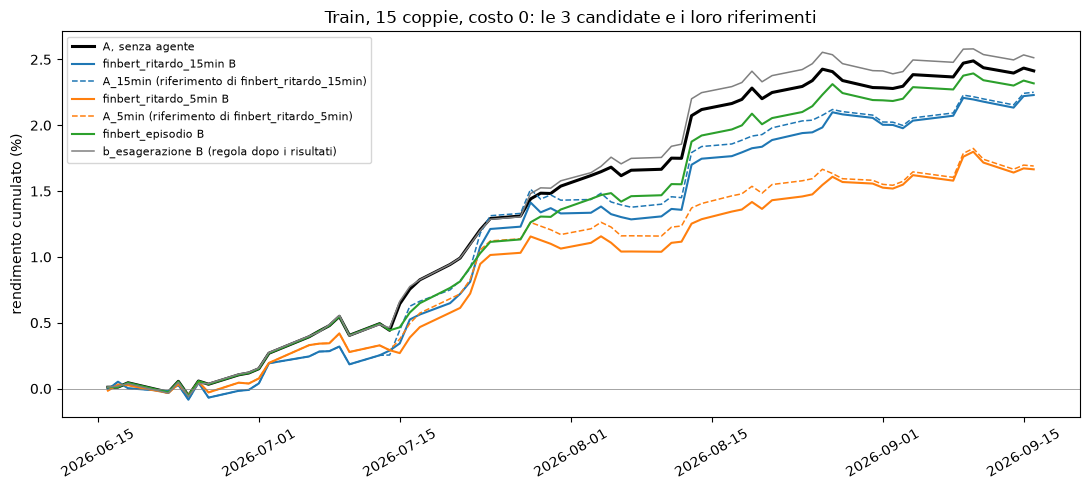

In [12]:
by_key = {(v.nome, v.versione): v for v in varianti}
eq = lambda t: daily_pnl(add_costs(t, 0), days).equity * 100   # noqa: E731
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(days, eq(A), color="black", lw=2.2, label="A, senza agente")
for color, key in zip(("tab:blue", "tab:orange", "tab:green"), candidate.index):
    v = by_key[key]
    ax.plot(days, eq(v.trades), color=color, lw=1.5, label=f"{v.nome} {v.versione}")
    if v.riferimento != "A":
        ax.plot(days, eq(rif[v.riferimento]), color=color, lw=1.1, ls="--", label=f"{v.riferimento} (riferimento di {v.nome})")
ax.plot(days, eq(by_key[("b_esagerazione", "B")].trades), color="grey", lw=1.1, label="b_esagerazione B (regola dopo i risultati)")
ax.axhline(0, color="grey", lw=0.5)
ax.set_ylabel("rendimento cumulato (%)")
ax.set_title("Train, 15 coppie, costo 0: le 3 candidate e i loro riferimenti")
ax.tick_params(axis="x", rotation=30)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS / "curve_capitale.png", dpi=120)
plt.show()

## 6. Salvataggio

Tabelle in `Results/`, trade e decisioni dei set di decisioni nelle loro cartelle in `Results/varianti_agente/`, tutto su git.

In [13]:
tables = {"A_per_costo": by_cost(A, days), "A_per_coppia": by_group(A, "pair", cost_bps=0), "trades_A": A, "confronto_versioni": cmp,
          "bloccati_contro_caso": valuta_blocchi(varianti, rif), "notizia_giusta_C": valuta_segui(varianti, rif),
          "candidate": candidate, "B_e_C_per_variante": per_variante(cmp, valuta_segui(varianti, rif))}
for name in available_versions(complete=True):
    for letter, t in version_trades(trades, name).items():
        if letter != "A":
            tables[f"varianti_agente/{name}/trades_{letter}"] = t
    copy = VERSIONS[name]["copy"]
    if not version_file(name)[1] and copy is not None and copy.name == "decisioni.csv":
        tables[f"varianti_agente/{name}/decisioni"] = load_version(name)    # aggiorna la copia su git dal file originale
for p in save_results(tables):
    print(p.relative_to(RESULTS.parent))

Results/A_per_costo.csv
Results/A_per_coppia.csv
Results/trades_A.csv
Results/confronto_versioni.csv
Results/bloccati_contro_caso.csv
Results/notizia_giusta_C.csv
Results/candidate.csv
Results/B_e_C_per_variante.csv
Results/varianti_agente/spark_24h/trades_B.csv
Results/varianti_agente/spark_24h/trades_C.csv
Results/varianti_agente/spark_6h/trades_B.csv
Results/varianti_agente/spark_6h/trades_C.csv
Results/varianti_agente/lessico/trades_B.csv
Results/varianti_agente/lessico/trades_C.csv
Results/varianti_agente/3b_6h/trades_B.csv
Results/varianti_agente/finbert_seduta/trades_B.csv
Results/varianti_agente/finbert_seduta/trades_C.csv
Results/varianti_agente/c_fresca/trades_C.csv
Results/varianti_agente/finbert_episodio/trades_B.csv
Results/varianti_agente/finbert_episodio/trades_C.csv


## 7. Cosa ci dicono i risultati

Numeri delle tabelle qui sopra: train, 15 coppie, 973 segnali, costo 0 salvo dove è detto.

**Versione A.** 973 trade con +7,44 punti base lordi ciascuno: +7.239 dollari su 300.000 in 64 giorni (+2,4%). Guadagnano i trade che rientrano (+38,8 bps) e gli ingressi nel gap della notte (11,4 bps contro 3,9 dopo i primi 30 minuti). Due coppie, PYPL-XYZ e CRM-WDAY, fanno quasi metà del guadagno lordo. Il pareggio è a 1,86 bps per operazione: a 5 bps la A perde 12.221 dollari. Aspettare prima di entrare costa: 2.168 dollari con 5 minuti, 487 con 15.

**Confronto.** Nessuna variante con la regola scritta prima batte il suo riferimento.
- In cima alla classifica c'è `c_fresca`, che però coincide con la A: sul train non trova mai una notizia da seguire.
- Vengono poi le B con ingresso ritardato (-63 e -75 dollari rispetto alla loro A ritardata) e `finbert_episodio` B (-285).
- Le B di `finbert_seduta` e `3b_6h` perdono circa 500 dollari; quelle di `spark_24h`, `spark_6h` e `lessico` tra 1.334 e 1.527.
- Le C fanno peggio delle B con le stesse decisioni: fino a -3.444 dollari.
- Ridurre a metà invece di bloccare limita la perdita, ma non la elimina.

L'unica sopra la A è `b_esagerazione` (+300 dollari), costruita guardando proprio questi risultati.

**Candidate per il test.** Escluse `b_esagerazione` (regola scritta dopo i risultati) e `c_fresca` (identica alla A), le prime 3 B sono `finbert_ritardo_15min` (-63 $), `finbert_ritardo_5min` (-75 $) e `finbert_episodio` (-285 $). Le differenze tra loro sono dentro il rumore (Passaggio 7).

**Variante scelta: `finbert_episodio`.** Sul test si porta una sola variante con la sua B e la sua C, quindi le si guarda insieme (tabella "B e C della stessa variante"):
- ha la C migliore (-651 $, notizia giusta nel 55% dei casi) e la posizione media migliore tra B e C;
- entra al momento del segnale, come la A, quindi il confronto A, B, C sul test è diretto. Le varianti ritardate si confrontano invece con una A ritardata, e l'attesa da sola costa rispetto alla A: 487 $ con 15 minuti, 2.168 $ con 5;
- sulla somma B + C è seconda dietro `finbert_ritardo_5min`, per 73 $: è rumore.

Il criterio (dollari a costo 0 rispetto al riferimento, solo regole scritte prima) è stato precisato dopo aver visto il train, ma prima del test: si sceglie la variante intera, con lo stesso ingresso della A. Va dichiarato nel report.

**PYPL-XYZ.** Le candidate perdono rispetto al riferimento quasi solo per un blocco su PYPL-XYZ, il 15 luglio. La coppia non si esclude:
- toglierla dopo aver visto i risultati vorrebbe dire adattare la strategia al train;
- toglierebbe anche la coppia che guadagna di più nella A.

La dipendenza da questa coppia si dichiara nel report (Passaggio 7).

**In sintesi.** Sul train nessun uso delle notizie migliora la strategia in modo visibile. Sul test si porta `finbert_episodio`, con A, B e C, una volta sola.

**Limiti.**
- Solo train, su cui sono stati scelti segnale e regole: risultati ottimistici. Con 21 varianti provate, la migliore lo è anche per caso.
- Pochi blocchi (4-166) e pochi `segui` (0-61).
- Costi stimati, nessun costo di prestito dei titoli.
- I modelli possono conoscere gli eventi del periodo (lookahead).
- I set sui 40 segnali del campione non sono qui: sul campione l'agente e il gruppo prendevano la stessa decisione 38 volte su 40 (`Results/confronto_campione_40.csv`).